In [2]:
%load_ext autoreload
%autoreload 2

from funkcje.funkcje import *
from funkcje.wskazniki_kredytowe import oblicz_wskazniki
from funkcje.do_pipeline import *

In [3]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score,average_precision_score, roc_auc_score, brier_score_loss, log_loss, roc_curve
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from scipy.special import logit, expit
from scipy.optimize import brentq
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold

In [4]:
#Dane
df = pd.read_csv("zbior_1.csv")
#usuwam wybrane zmienne kategoryczne na podstawie tego co w eksploracja_danych.ipynb
X=df.iloc[:, :-1].drop(columns=["szczegolnaFormaPrawna_Symbol", "schemat_wsk_rzis","schemat_wsk_bilans"])
X=oblicz_wskazniki(X)
y=df.iloc[:, -1]

#Podzil na zbior treningowy (70%) i pozostale
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=2137,
    stratify=y
)

#Podzil na zbior walidacyjny (15%) i testowy (15%)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=2137,
    stratify=y_temp
)

KOL = {"train": "#3E5C76", "valid": "#C9A227", "test": "#A3262C", "logit": "#3E5C76", "black-box": "#A3262C"}
TARGET_PD = 0.04 

# Finalny model regresji

In [5]:

regresja_logistyczna_pipeline = Pipeline([
    ("przygotowanie_cech", PrzygotowanieCech([])),
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegressionUjemne(
        l1_ratio=1, solver="liblinear", C=100, random_state=2137, max_iter=1000
    )),
])

In [6]:
params={'classifier__C': np.float64(0.1),
  'przygotowanie_cech__liczba_kwantyli': np.int64(10),
  'przygotowanie_cech__prog_auc': np.float64(0.55),
  'przygotowanie_cech__prog_korelacji': np.float64(0.7),
  'przygotowanie_cech__prog_monotonicznosci': np.float64(0.1),
  'przygotowanie_cech__prog_nan': np.float64(0.35),
  'przygotowanie_cech__prog_zer': np.float64(0.3),
  'przygotowanie_cech__tylko_wskazniki': np.False_}
regresja_logistyczna = clone(regresja_logistyczna_pipeline)
regresja_logistyczna.set_params(**params)
regresja_logistyczna.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('przygotowanie_cech', ...), ('imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,kolumny_do_pominiecia,[]
,prog_korelacji,np.float64(0.7)
,prog_auc,np.float64(0.55)
,prog_nan,np.float64(0.35)
,prog_zer,np.float64(0.3)


In [7]:
betas = regresja_logistyczna.named_steps["classifier"].coef_[0]

In [8]:
#liczb niezerowych bet
np.sum(betas != 0)

np.int64(15)

In [9]:
#liczba dodatnich bet
np.sum(betas>0)

np.int64(0)

In [10]:
P = {"logit": {s: regresja_logistyczna.predict_proba(X)[:, 1] for s, X in [("train", X_train), ("valid", X_valid), ("test", X_test)]}}
print(f"AUC na zbiorze walidacyjnym: {roc_auc_score(y_valid, P['logit']['valid'])}")
print(f"AUC na zbiorze testowym: {roc_auc_score(y_test, P['logit']['test'])}")

AUC na zbiorze walidacyjnym: 0.8060975609756098
AUC na zbiorze testowym: 0.7806475762680142


In [11]:
#Wypisanie nazw cech, które mają niezerowe współczynniki i ich współczynniki
kolumny_wynikowe = regresja_logistyczna.named_steps["przygotowanie_cech"].kolumny_wynikowe_
kolumny_niezerowe = [kolumny_wynikowe[i] for i in range(len(betas)) if betas[i] != 0]
betas_niezerowe = [betas[i] for i in range(len(betas)) if betas[i] != 0]
print("Cechy z niezerowymi współczynnikami:")
for i, kolumna in enumerate(kolumny_niezerowe):
    print(f"{kolumna}: {betas_niezerowe[i]}")

Cechy z niezerowymi współczynnikami:
-wsk_index_skr_zaw: -0.33866186753142863
-wsk_index_nowe: -0.2956302918937439
wsk_akt_generowania_got_1: -0.14642682537039303
wsk_marza_ebitda_2: -0.03239669762917381
wsk_rent_kapitalu: -0.02367825221631957
wsk_zysk_operacyjny_zob_1: -0.010290587725583155
wsk_ebitda_zobowiazan_3: -0.01548353359234864
wsk_kredyt_zobowiazania_ebitda: -0.03487389552457176
-Aktywa_spadek: -0.37930162783663823
-wsk_pokrycie_aktywow_tr_kapitalem_st_wzrost: -0.08626747340822327
-wsk_ebitda_zobowiazan_odsetki_4_spadek: -0.28128052029063655
-wsk_cykl_konwersji_gotowki_wzrost: -0.00198234341336968
-wsk_zadluzenia_wzrost: -0.3747985664063848
-wsk_fin_majatku_kapitalem_spadek: -0.016037292521060176
wsk_fin_majatku_kapitalem_wzrost: -0.11163620050088924


# Finalny model black-box

In [12]:
xgboost_pipeline=Pipeline([
    ("przygotowanie_cech", PrzygotowanieCech_xgb()),
    ("classifier", XGBClassifier(
        enable_categorical=True,
        tree_method="hist",
        random_state=2137)
    )
])
prams_xgb={'classifier__colsample_bytree': 1.0, 'classifier__gamma': 1, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 400, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 10, 'classifier__subsample': 1.0, 'przygotowanie_cech__prog_korelacji': 0.7, 'przygotowanie_cech__prog_nan': 0.25, 'przygotowanie_cech__prog_zer': 0.3, 'przygotowanie_cech__uwzglednij_kategoryczne': False}

In [13]:
black_box = clone(xgboost_pipeline)
black_box.set_params(**prams_xgb)
black_box.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('przygotowanie_cech', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,prog_korelacji,0.7
,prog_nan,0.25
,prog_zer,0.3
,uwzglednij_kategoryczne,False
,kolumny_do_pominiecia,None


In [14]:
P["black-box"] = {s: black_box.predict_proba(X)[:, 1] for s, X in [("train", X_train), ("valid", X_valid), ("test", X_test)]}

print(f"AUC na zbiorze walidacyjnym: {roc_auc_score(y_valid, P['black-box']['valid'])}")
print(f"AUC na zbiorze testowym: {roc_auc_score(y_test, P['black-box']['test'])}")

AUC na zbiorze walidacyjnym: 0.8396951219512194
AUC na zbiorze testowym: 0.7958075987273068


# Kalibraja

### Funkcja z laboratoriów

In [15]:
#Do oceny przed kalibracja
EPS=1e-6
def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))
def reliability(ax, y_true, p, label, n_bins=10, **kw):
    obs, pred = calibration_curve(y_true, p, n_bins=n_bins, strategy="quantile")
    ax.plot(pred, obs, marker="o", label=label, **kw)

def os_log(ax, lo=2e-3, hi=1.0):
    ax.plot([lo, hi], [lo, hi], "--", color="gray", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("średnie PD w przedziale"); ax.set_ylabel("obserwowany DR"); ax.grid(alpha=0.3, which="both")
    
def raport_kalibracji(y_true, modele, tytul="Kalibracja na zbiorze testowym"):
    # modele: słownik {nazwa: PD}; zwraca tabelę miar i rysuje reliability diagram
    y_true = np.asarray(y_true)
    tab_r = pd.DataFrame({k: miary(y_true, np.asarray(v)) for k, v in modele.items()}).T
    tab_r.insert(0, "DR", y_true.mean())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for k, v in modele.items():
        reliability(axes[0], y_true, np.asarray(v), k)
        axes[1].hist(np.asarray(v), bins=np.logspace(-3.5, 0, 50), histtype="step", lw=2, label=k)
    os_log(axes[0]); axes[0].set_title(tytul); axes[0].legend()
    axes[1].set_xscale("log"); axes[1].set_xlabel("PD"); axes[1].set_title("Rozkład PD"); axes[1].legend()
    plt.tight_layout(); plt.show()
    return tab_r

def ece(y_true, p, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    return float(sum(np.mean(idx == m) * abs(y_true[idx == m].mean() - p[idx == m].mean())
                     for m in range(n_bins) if np.any(idx == m)))

def przedzialy_rowne_liczebnie(p, n_bins=10):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    return np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2), len(edges) - 1

def ace(y_true, p, n_bins=10):
    idx, k = przedzialy_rowne_liczebnie(p, n_bins)
    return float(sum(np.mean(idx == m) * abs(y_true[idx == m].mean() - p[idx == m].mean()) for m in range(k) if np.any(idx == m)))

def murphy(y_true, p, n_bins=10):
    idx, k = przedzialy_rowne_liczebnie(p, n_bins)
    o = y_true.mean(); rel = res = 0.0
    for m in range(k):
        msk = idx == m
        if msk.any():
            w = msk.mean(); rel += w * (p[msk].mean() - y_true[msk].mean()) ** 2; res += w * (y_true[msk].mean() - o) ** 2
    return rel, res, o * (1 - o)

def cox(y_true, p):
    z = logit(np.clip(p, EPS, 1 - EPS))
    a = brentq(lambda d: expit(z + d).mean() - y_true.mean(), -15, 15)        # wyraz wolny przy nachyleniu = 1
    if np.ptp(z) < 1e-9:                                                       # stałe PD - nachylenie nieokreślone
        return a, np.nan
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y_true).coef_[0, 0]
    return a, b

def miary(y_true, p):
    y_true = np.asarray(y_true); p = np.asarray(p); a, b = cox(y_true, p)
    return {"średnie PD": p.mean(), "AUC": roc_auc_score(y_true, p), "Brier": brier_score_loss(y_true, p),
            "log-loss": log_loss(y_true, np.clip(p, EPS, 1 - EPS)), "ECE": ece(y_true, p), "ACE": ace(y_true, p),
            "CITL a": a, "nachylenie b": b}


def metryki(y, p):
    y, p = np.asarray(y), np.asarray(p); auc = roc_auc_score(y, p)
    return {"n": len(y), "DR": y.mean(), "średnie PD": p.mean(), "AUC": auc, "Gini": 2 * auc - 1, "KS": ks(y, p),
            "PR-AUC": average_precision_score(y, p), "log-loss": log_loss(y, np.clip(p, EPS, 1 - EPS)),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p), "ACE": ace(y, p)}

#Do kalibracji krztałtu

def _z(p):
    return logit(np.clip(p, EPS, 1 - EPS))

def _beta_cechy(p):
    p = np.clip(p, EPS, 1 - EPS); return np.column_stack([np.log(p), -np.log(1 - p)])

FIT = {
    "bez kalibracji": lambda y, p: None,
    "Platt": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_z(p).reshape(-1, 1), y),
    "izotoniczna": lambda y, p: IsotonicRegression(out_of_bounds="clip", y_min=EPS, y_max=1 - EPS).fit(p, y),
    "beta": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_beta_cechy(p), y),
}

def zastosuj(metoda, kal, p):
    if metoda == "bez kalibracji":
        return np.asarray(p)
    if metoda == "Platt":
        return kal.predict_proba(_z(p).reshape(-1, 1))[:, 1]
    if metoda == "beta":
        return kal.predict_proba(_beta_cechy(p))[:, 1]
    return kal.predict(p)

def cv_logloss(metoda, y, p, k=5):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=2137); ll = []
    for a, b in skf.split(p.reshape(-1, 1), y):
        q = zastosuj(metoda, FIT[metoda](y[a], p[a]), p[b])
        ll.append(log_loss(y[b], np.clip(q, EPS, 1 - EPS)))
    return float(np.mean(ll))

#zmodyfikowane by działało
def cv_logloss(metoda, y, p, k=5):
    y = np.asarray(y)
    p = np.asarray(p)

    skf = StratifiedKFold(
        n_splits=k,
        shuffle=True,
        random_state=2137
    )
    ll = []

    for a, b in skf.split(p.reshape(-1, 1), y):
        q = zastosuj(metoda, FIT[metoda](y[a], p[a]), p[b])
        ll.append(log_loss(y[b], np.clip(q, EPS, 1 - EPS)))

    return float(np.mean(ll))

#Do kalibracji poziomu
def delta_do_sredniej(p, cel, lo=-15.0, hi=15.0, iters=100):
    z = _z(p)
    for _ in range(iters):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if expit(z + mid).mean() < cel else (lo, mid)
    return (lo + hi) / 2

## Diagnostyka przed klibracją

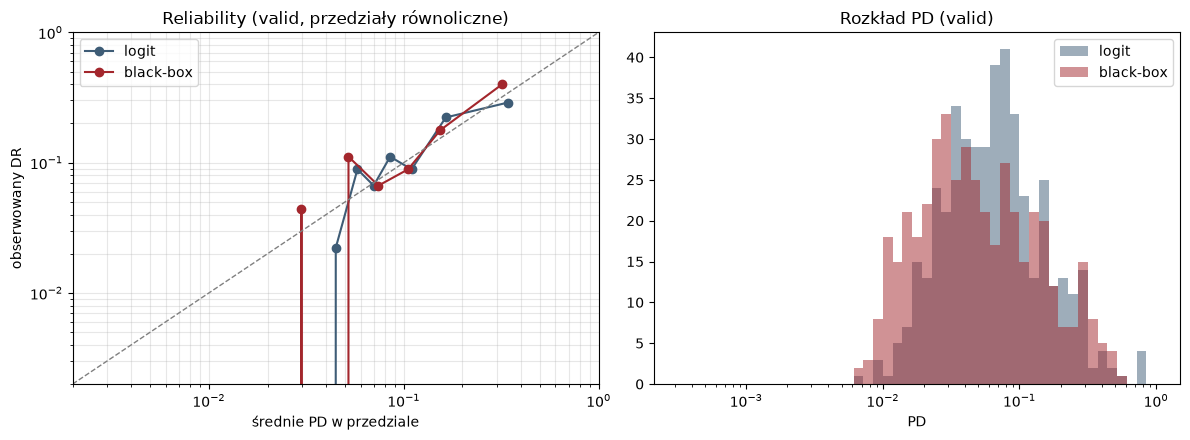

,DR,średnie PD,Brier,ECE,ACE,log-loss
logit,0.0889,0.0951,0.0704,0.0215,0.0292,0.2482
black-box,0.0889,0.0826,0.0667,0.0154,0.0291,0.2327


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m in ["logit", "black-box"]:
    reliability(axes[0], y_valid, P[m]["valid"], m, color=KOL[m])
    axes[1].hist(P[m]["valid"], bins=np.logspace(-3.5, 0, 50), alpha=0.5, label=m, color=KOL[m])
os_log(axes[0]); axes[0].set_title("Reliability (valid, przedziały równoliczne)"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_xlabel("PD"); axes[1].set_title("Rozkład PD (valid)"); axes[1].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame({m: metryki(y_valid, P[m]["valid"]) for m in ["logit", "black-box"]}).T[["DR", "średnie PD", "Brier", "ECE", "ACE", "log-loss"]].round(4))

## Kalibracja krztałtu

In [17]:
wybor = pd.DataFrame({m: {met: cv_logloss(met, y_valid, P[m]["valid"]) for met in FIT} for m in ["logit", "black-box"]}).T
display(wybor.round(5))

,bez kalibracji,Platt,izotoniczna,beta
logit,0.24817,0.25060,0.28765,0.25541
black-box,0.23274,0.23339,0.30365,0.23597


Czyli black-box i regresja logistyczna nie wymagają kalibracji krztałtu.

## Kalibracja poziomu

In [18]:
P4 = {}

for MODEL in ["logit", "black-box"]:
    PS = {s: np.asarray(P[MODEL][s]) for s in ["train", "valid", "test"]}
    DELTA = delta_do_sredniej(PS["valid"], TARGET_PD)
    P4[MODEL] = {s: expit(_z(PS[s]) + DELTA) for s in PS}

    print(f"Model: {MODEL}, kalibracja: bez kalibracji, δ = {DELTA:+.3f}")
    print(f"Średnie PD na valid: {P[MODEL]['valid'].mean():.2%} (model) -> {P4[MODEL]['valid'].mean():.2%} (po δ)")

    wiersze_kal = {"test - model bez kalibracji": metryki(y_test, P[MODEL]["test"])}
    wiersze_kal["test - kształt + przesunięcie do 4%"] = metryki(y_test, P4[MODEL]["test"])

    tab_kal = pd.DataFrame(wiersze_kal).T[["DR", "średnie PD", "AUC", "Brier", "ECE", "ACE", "log-loss"]]
    display(tab_kal.round(4))

Model: logit, kalibracja: bez kalibracji, δ = -1.045
Średnie PD na valid: 9.51% (model) -> 4.00% (po δ)


,DR,średnie PD,AUC,Brier,ECE,ACE,log-loss
test - model bez kalibracji,0.0867,0.0988,0.7806,0.0721,0.0423,0.0299,0.2567
test - kształt + przesunięcie do 4%,0.0867,0.0411,0.7806,0.0762,0.0527,0.0513,0.2780


Model: black-box, kalibracja: bez kalibracji, δ = -0.848
Średnie PD na valid: 8.26% (model) -> 4.00% (po δ)


,DR,średnie PD,AUC,Brier,ECE,ACE,log-loss
test - model bez kalibracji,0.0867,0.088,0.7958,0.0629,0.0283,0.0403,0.2333
test - kształt + przesunięcie do 4%,0.0867,0.043,0.7958,0.0688,0.0436,0.0568,0.2531


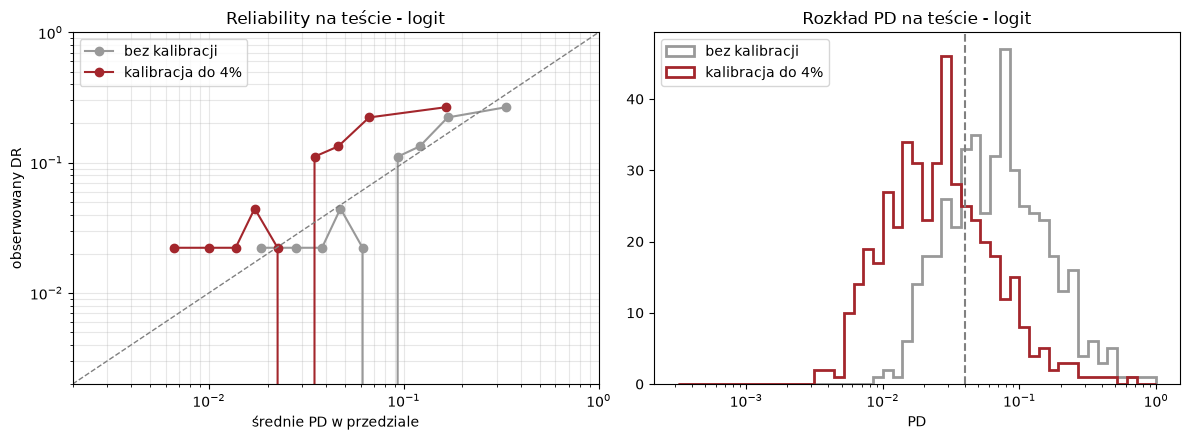

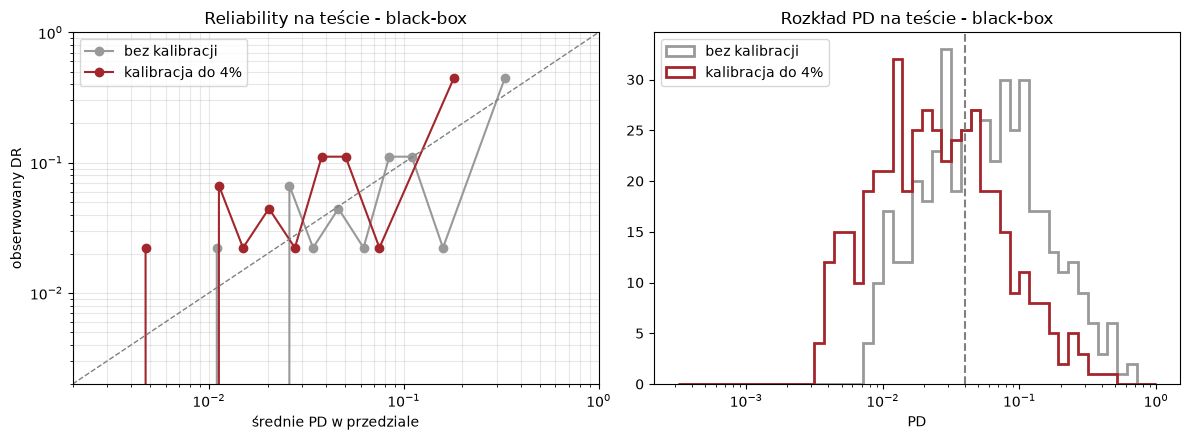

In [27]:
for MODEL in ["logit", "black-box"]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    serie = [
        (P[MODEL]["test"], "bez kalibracji", "#999999"),
        (P4[MODEL]["test"], "kalibracja do 4%", KOL["test"])
    ]

    for p, lab, col in serie:
        reliability(axes[0], y_test, p, lab, color=col)
        axes[1].hist(
            p, bins=np.logspace(-3.5, 0, 50),
            histtype="step", lw=2, label=lab, color=col
        )

    os_log(axes[0])
    axes[0].set_title(f"Reliability na teście - {MODEL}")
    axes[0].legend()

    axes[1].set_xscale("log")
    axes[1].axvline(TARGET_PD, ls="--", color="gray")
    axes[1].set_xlabel("PD")
    axes[1].set_title(f"Rozkład PD na teście - {MODEL}")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# SHAP

In [20]:
import shap

In [24]:
# Wyciągnięcie wytrenowanego modelu
model = black_box.named_steps["classifier"]

# Przekształcenie danych przez wcześniejsze etapy pipeline
X_transformed = black_box[:-1].transform(X_test)

#nazy kolun
feature_names=black_box.named_steps["przygotowanie_cech"].kolumny_wynikowe_

X_transformed = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X_test.index
)

#obliczenie wartości SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_transformed)

In [34]:
shap_values

.values =
array([[ 4.4005848e-02,  6.0189140e-01,  3.8638934e-01, ...,
        -5.5327103e-03, -2.4673983e-03,  2.1003155e-01],
       [-3.5958819e-02, -4.1372272e-01, -6.3861656e-01, ...,
         2.0884780e-02, -1.3083863e-02,  1.0865715e-01],
       [-3.0907307e-02, -5.6713283e-01, -6.9246018e-01, ...,
        -5.5327103e-03, -1.3083863e-02,  9.5852800e-02],
       ...,
       [ 1.1810724e-02,  4.0836290e-01, -3.1662518e-01, ...,
         2.3981580e-04, -2.4673983e-03, -2.6396822e-02],
       [-6.6306822e-02, -5.0507009e-01, -4.7741473e-01, ...,
         2.0884780e-02, -1.3083863e-02, -2.4528356e-02],
       [-2.1327011e-01,  6.6049629e-01,  6.2027878e-01, ...,
        -5.5327103e-03, -2.4673983e-03,  5.3152908e-04]],
      shape=(450, 44), dtype=float32)

.base_values =
array([-2.3633294, -2.3633294, -2.3633294, -2.3633294, -2.3633294,
       -2.3633294, -2.3633294, -2.3633294, -2.3633294, -2.3633294,
       -2.3633294, -2.3633294, -2.3633294, -2.3633294, -2.3633294,
       -2.3633

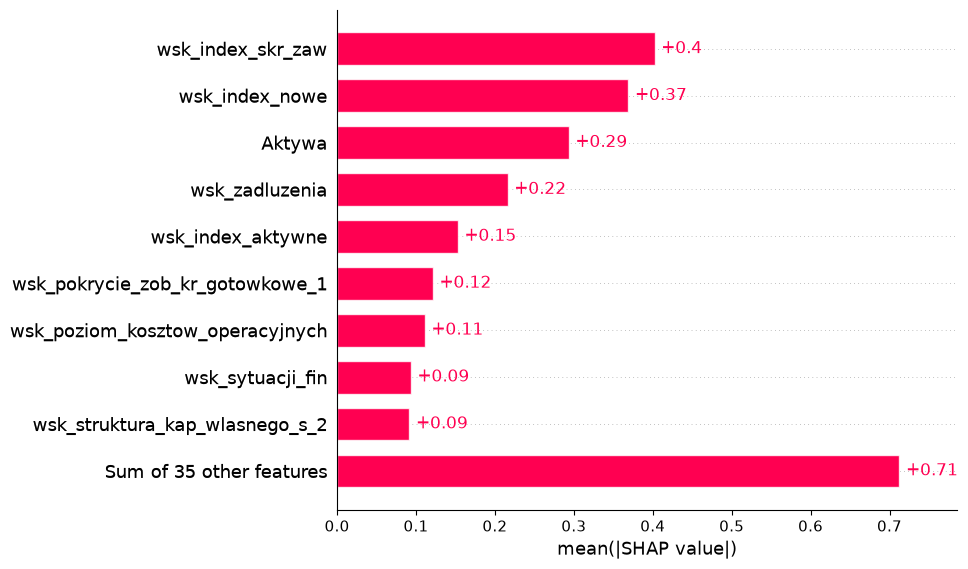

In [30]:
shap.plots.bar(shap_values)

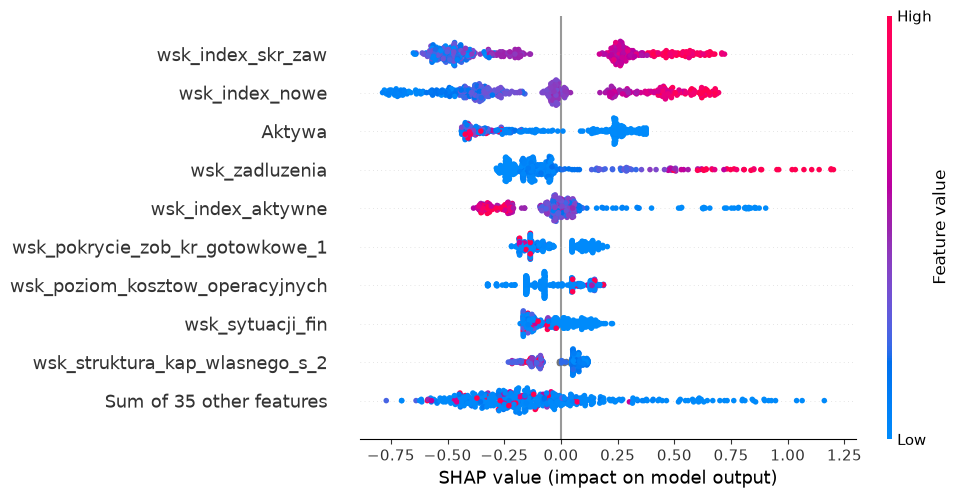

In [35]:
shap.plots.beeswarm(shap_values)

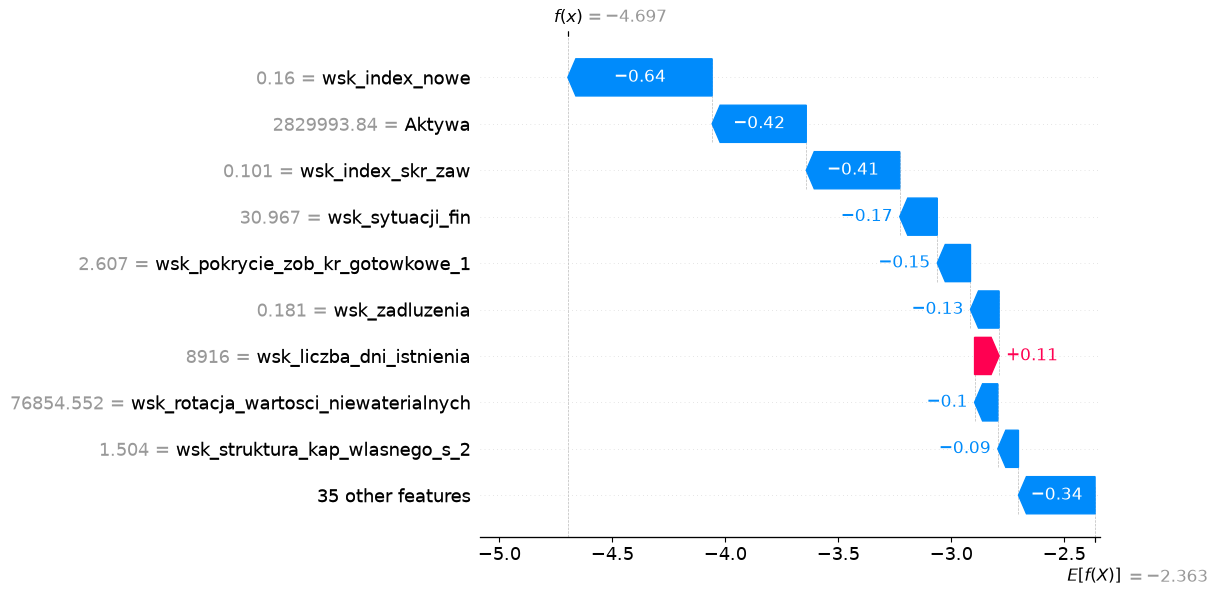

In [31]:
shap.plots.waterfall(shap_values[1])